# Week 4 - Task 6: final model selection, hold-out scoring, serialization

**Protocol:** w4-v1 (`TUNING_PROTOCOL.md`) | **Data:** 5 Cairo stations, PM2.5 at t+1 / t+2 / t+3 days

| Part | Question | Output |
|---|---|---|
| 1 | Which model goes to production, per horizon and task? | rubric table + sensitivity |
| 2 | How does accuracy degrade with the horizon? | table + chart vs naive baselines |
| 3 | What does the health-risk alert do at the final thresholds? | confusion matrices + PR curves |
| 4 | Where do the models fail? (from Task 5) | station / season tables |
| 5 | Are the serialized models correct? | reload + ONNX checks |
| 6 | What is the honest hold-out score? | tables vs CV (scored **once**) |

This notebook only **reads** the results written by `task6_01 ... task6_05` and loads the saved models. It never loads the hold-out: the hold-out was scored once by `task6_05_score_holdout.py` (lock file `artifacts/results/task6_holdout_SCORED.lock`) and the tables below come from the saved predictions.

Files needed next to it: `task6_common.py`, `tuning.py`, `splitting.py`, `data/tuning_set.parquet`, `artifacts/` (results, feature sets, task6 charts) and `models/`.

In [1]:
import warnings; warnings.filterwarnings("ignore")
import json
from pathlib import Path
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Image, Markdown
import joblib
import task6_common as c
from task6_common import tn, sp

R, FIG, M = c.RES, c.FIG, c.MODELS
H = c.H_LABEL
rd = lambda n: pd.read_csv(R / n)
pd.set_option("display.width", 200); pd.set_option("display.max_columns", 30); pd.set_option("display.max_colwidth", 60)
lock = (R / "task6_holdout_SCORED.lock").read_text().strip()
print("hold-out status:", lock.split("|")[0].strip(), "(scored once; this notebook does not load the hold-out)")
print("protocol:", tn.PROTOCOL_VERSION, "| CV:", tn.CV, "| precision floor:", tn.PRECISION_FLOOR)

hold-out status: scored 2026-10-31T17:14:36 (scored once; this notebook does not load the hold-out)
protocol: w4-v1 | CV: {'n_splits': 5, 'test_days': 90, 'min_train_days': 400} | precision floor: 0.75


## 1. Model selection

**Rubric.** Regression and classification are ranked separately (recall exists only for classifiers, RMSE only for regressors), so the brief's 40% recall + 30% RMSE become one *performance* weight.
- *Performance:* a candidate is better only if its mean CV RMSE is lower **and** it wins at least 4 of 5 folds (Task 3 rule); otherwise it is a **tie** and both score 100.
- *Speed and simplicity:* mean of three 0-100 ratios: inference time for 905 rows, model size, number of features.
- Weights: **70% performance / 30% speed and simplicity** (a proposal; the pick does not change for any weight from 50% to 90%, see below).
- Classification: only one family was tuned (XGBoost, Task 4; tied with LightGBM there, kept for simplicity), so there is nothing to rank.

,horizon,model,feature_set,n_features,cv_rmse_mean,cv_rmse_std,fold_wins_vs_other,latency_ms_905rows,size_kb,perf,speed_simplicity,total,picked
0,t+1 (24h),lightgbm,full,101,14.93,5.41,2,39.23,2161.04,100.0,72.61,91.78,False
1,t+1 (24h),xgboost,pruned,79,14.87,5.18,3,15.54,3168.68,100.0,89.40,96.82,True
2,t+2 (48h),lightgbm,pruned,79,16.91,6.14,2,5.15,108.21,100.0,100.00,100.00,True
3,t+2 (48h),xgboost,pruned,79,17.03,6.44,3,8.05,674.73,100.0,60.03,88.01,False
4,t+3 (72h),lightgbm,pruned,79,17.53,6.69,3,14.12,378.03,100.0,86.68,96.01,True
5,t+3 (72h),xgboost,pruned,79,17.52,6.51,2,8.48,1285.67,100.0,76.47,92.94,False


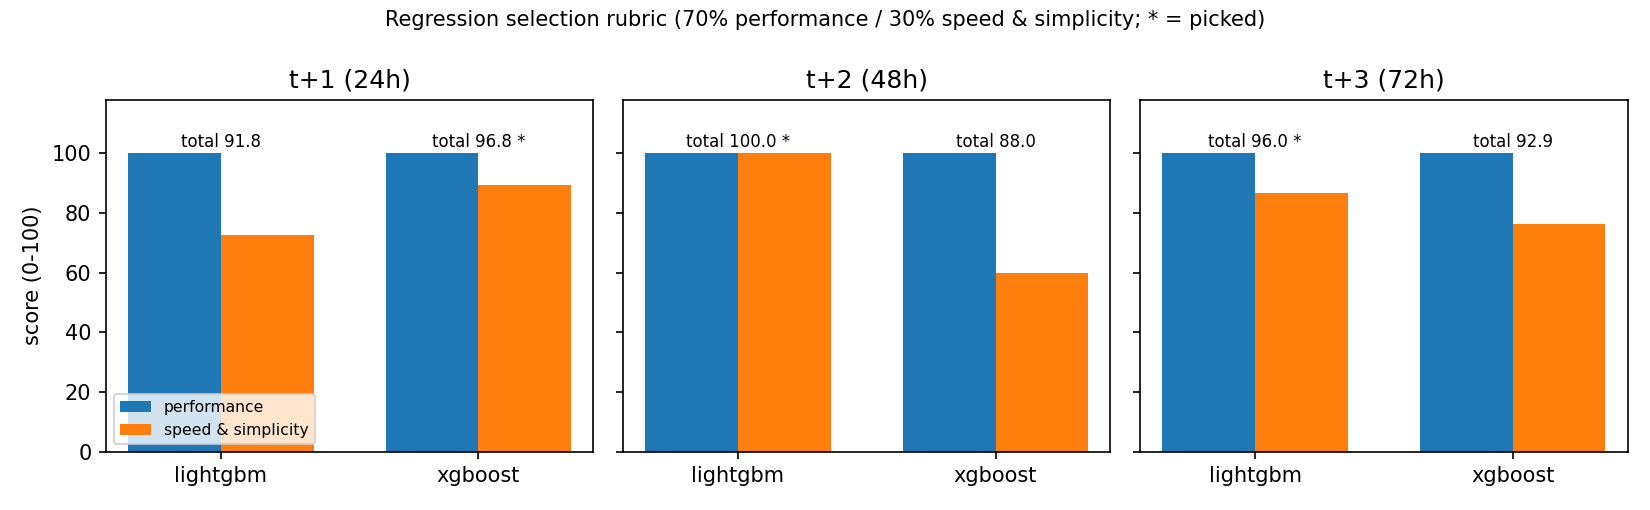

In [2]:
cand = rd("task6_reg_candidates.csv"); msel = rd("task6_model_selection.csv"); sens = rd("task6_selection_sensitivity.csv")
sel = json.loads((R / "task6_selection.json").read_text())
rub = msel[msel.variant.str.startswith("rubric")].copy()
rub["horizon"] = rub.horizon.map(H)
rub = rub.merge(cand[["horizon", "model", "n_features", "latency_ms_905rows", "size_kb"]].assign(horizon=lambda d: d.horizon.map(H)), on=["horizon", "model"])
display(rub[["horizon", "model", "feature_set", "n_features", "cv_rmse_mean", "cv_rmse_std", "fold_wins_vs_other", "latency_ms_905rows", "size_kb", "perf", "speed_simplicity", "total", "picked"]].round(2).reset_index(drop=True))
display(Image(filename=str(FIG / "selection_rubric.png")))

In [3]:
st = sens.pivot_table(index=["horizon", "ranking"], columns="w_perf", values="pick", aggfunc="first")
st.index = st.index.set_levels([H[i] for i in st.index.levels[0]], level=0) if False else st.index
print("Pick by weight on performance ('tie (exact)' = identical scores). The picks are the same for every weight from 50% to 90%.")
display(st)
final = pd.DataFrame([dict(horizon=H[int(h)], regression=f"{v['regression']['model']} ({v['regression']['feature_set']})", cv_rmse=round(v['regression']['cv_rmse_mean'], 2),
                           classifier=f"{v['classification']['model']} ({v['classification']['feature_set']}), alert at p >= {v['classification']['threshold']:.3f}, imbalance: {v['classification']['imbalance']}") for h, v in sel["choice"].items()])
print("FINAL PRODUCTION MODELS"); display(final)

Pick by weight on performance ('tie (exact)' = identical scores). The picks are the same for every weight from 50% to 90%.


w_perf                 0.5       0.6       0.7       0.8       0.9          1.0
horizon ranking                                                                
1       raw        xgboost   xgboost   xgboost   xgboost   xgboost      xgboost
        tie rule   xgboost   xgboost   xgboost   xgboost   xgboost  tie (exact)
2       raw       lightgbm  lightgbm  lightgbm  lightgbm  lightgbm     lightgbm
        tie rule  lightgbm  lightgbm  lightgbm  lightgbm  lightgbm  tie (exact)
3       raw       lightgbm  lightgbm  lightgbm  lightgbm  lightgbm      xgboost
        tie rule  lightgbm  lightgbm  lightgbm  lightgbm  lightgbm  tie (exact)

FINAL PRODUCTION MODELS


,horizon,regression,cv_rmse,classifier
0,t+1 (24h),xgboost (pruned),14.87,"xgboost (pruned), alert at p >= 0.601, imbalance: none"
1,t+2 (48h),lightgbm (pruned),16.91,"xgboost (pruned), alert at p >= 0.804, imbalance: class_..."
2,t+3 (72h),lightgbm (pruned),17.53,"xgboost (pruned), alert at p >= 0.866, imbalance: class_..."


## 2. Accuracy by forecast horizon
The naive baselines use the same folds: *persistence* predicts tomorrow's PM2.5 as today's, *station mean* predicts the training-fold mean of the station.

,horizon,model_cv_rmse,persistence,station_mean,change_vs_previous,skill_vs_persistence
0,t+1 (24h),14.870,15.564,19.572,NaN,0.045
1,t+2 (48h),16.909,20.178,19.582,0.137,0.162
2,t+3 (72h),17.533,22.232,19.593,0.037,0.211


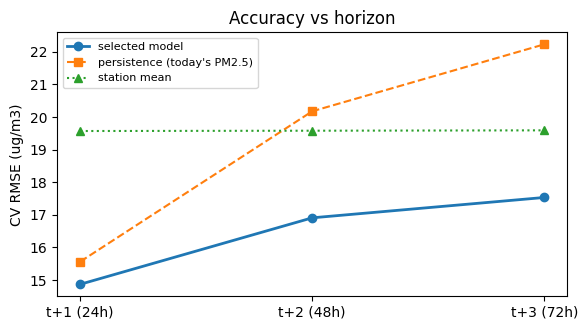

per-fold RMSE at t+1 (fold 1 winter, 2 spring, 3 summer, 4 autumn, 5 winter):


fold,1,2,3,4,5
candidate,,,,,
lightgbm,17.07,14.26,8.29,11.02,23.98
persistence (today's PM2.5),18.59,16.28,8.05,11.01,23.90
xgboost,17.12,14.19,8.27,11.36,23.41


In [4]:
folds = rd("task6_reg_cv_folds.csv")
picked = {int(h): v["regression"] for h, v in sel["choice"].items()}
rows = []
for h in c.HORIZONS:
    pm = folds[(folds.horizon == h) & (folds.candidate == "persistence (today's PM2.5)")].rmse.mean(); sm = folds[(folds.horizon == h) & (folds.candidate == "station mean (train fold)")].rmse.mean()
    rows.append(dict(horizon=H[h], model_cv_rmse=picked[h]["cv_rmse_mean"], persistence=pm, station_mean=sm, change_vs_previous=np.nan if h == 1 else picked[h]["cv_rmse_mean"] / picked[h - 1]["cv_rmse_mean"] - 1, skill_vs_persistence=1 - picked[h]["cv_rmse_mean"] / pm))
hz = pd.DataFrame(rows); display(hz.round(3))
fig, ax = plt.subplots(figsize=(6, 3.4)); x = np.arange(3)
ax.plot(x, hz.model_cv_rmse, "o-", lw=2, label="selected model"); ax.plot(x, hz.persistence, "s--", label="persistence (today's PM2.5)"); ax.plot(x, hz.station_mean, "^:", label="station mean")
ax.set_xticks(x); ax.set_xticklabels(hz.horizon); ax.set_ylabel("CV RMSE (ug/m3)"); ax.legend(fontsize=8); ax.set_title("Accuracy vs horizon"); plt.tight_layout(); plt.show()
print("per-fold RMSE at t+1 (fold 1 winter, 2 spring, 3 summer, 4 autumn, 5 winter):")
display(folds[(folds.horizon == 1) & folds.candidate.isin(["xgboost", "lightgbm", "persistence (today's PM2.5)"])].pivot_table(index="candidate", columns="fold", values="rmse").round(2))

**Reading:** most of the loss happens between t+1 and t+2. At t+1 the best model is only ~4% better than repeating today's value (and in the summer fold the naive rule is slightly better); the added value is at 48-72 h and in winter.

## 3. Health-risk alert at the final thresholds
Thresholds come from Task 4 (precision >= 0.75 on pooled out-of-fold predictions) and are **not** re-tuned on the hold-out.

,horizon,threshold,imbalance,TP,FP,FN,TN,precision,recall,auc_pooled
0,t+1 (24h),0.601,none,254,78,351,1567,0.765,0.420,0.864
1,t+2 (48h),0.804,class_weight,102,34,502,1612,0.750,0.169,0.811
2,t+3 (72h),0.866,class_weight,96,36,506,1612,0.727,0.159,0.763


Per 100 station-days:


,horizon,risk_days_per_100,alerts_per_100,false_alarms_per_100,missed_risk_days_per_100,correct_alerts_per_100
0,t+1 (24h),26.9,14.8,3.5,15.6,11.3
1,t+2 (48h),26.8,6.0,1.5,22.3,4.5
2,t+3 (72h),26.8,5.9,1.6,22.5,4.3


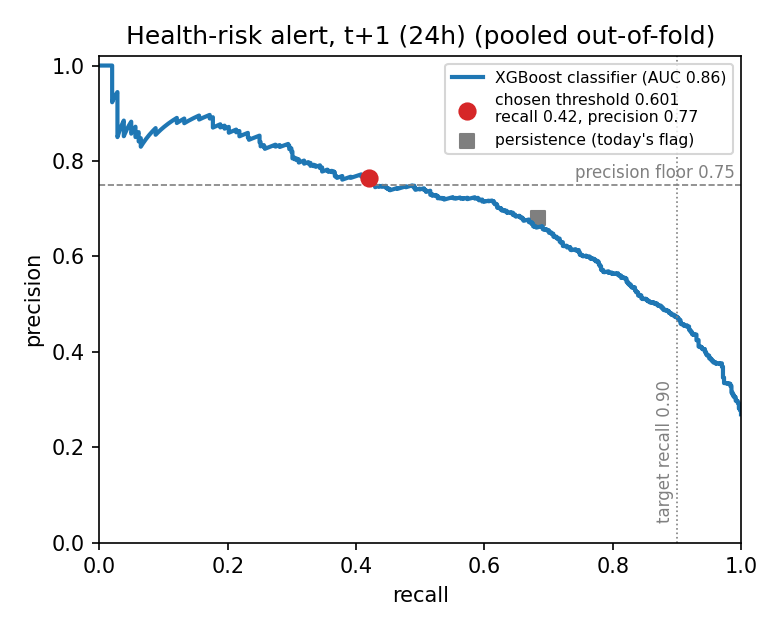

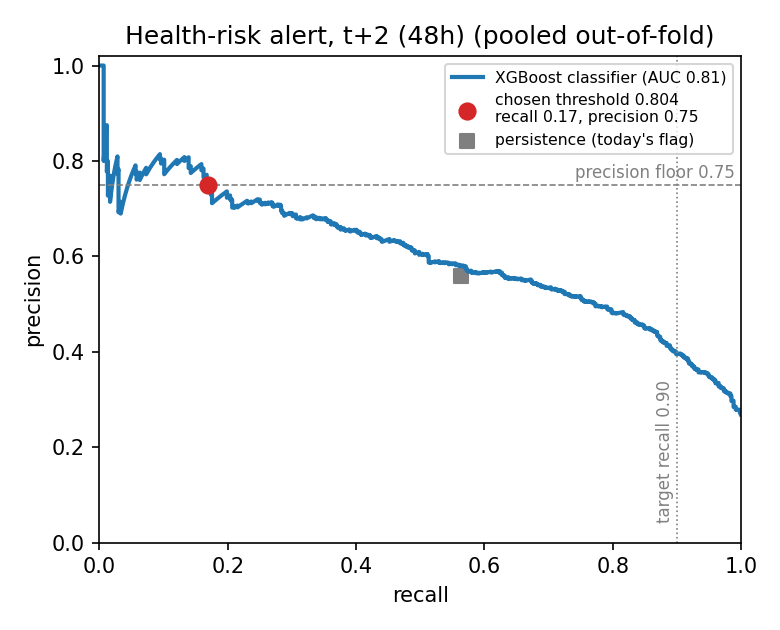

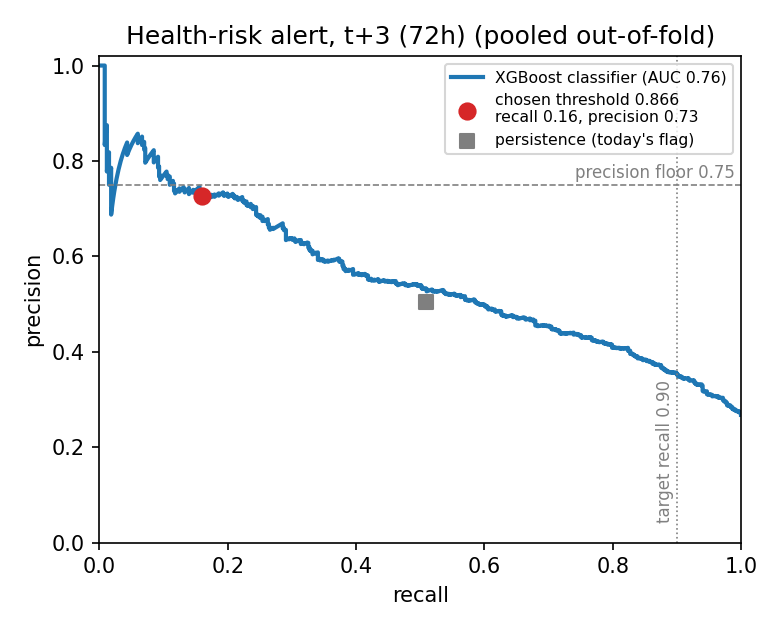

In [5]:
conf = rd("task6_clf_confusion.csv"); clfcv = rd("task6_clf_cv.csv"); oof = rd("task6_clf_oof.csv")
show = conf[["horizon", "threshold", "imbalance", "TP", "FP", "FN", "TN", "precision", "recall", "auc_pooled"]].copy(); show["horizon"] = show.horizon.map(H); display(show.round(3))
pl = conf[["horizon", "risk_days_per_100", "alerts_per_100", "false_alarms_per_100", "missed_risk_days_per_100"]].copy(); pl["correct_alerts_per_100"] = (conf.TP / conf.n * 100)
pl["horizon"] = pl.horizon.map(H); print("Per 100 station-days:"); display(pl.round(1))
for h in c.HORIZONS: display(Image(filename=str(FIG / f"pr_curve_h{h}.png"), width=420))

In [6]:
print("Per fold at the fixed thresholds (NaN precision = no alert fired). The alert almost never fires outside winter:")
d = clfcv.copy(); d["horizon"] = d.horizon.map(H); display(d[["horizon", "fold", "fold_season", "risk_days", "alerts", "TP", "FP", "FN", "precision", "recall"]].round(2))

Per fold at the fixed thresholds (NaN precision = no alert fired). The alert almost never fires outside winter:


,horizon,fold,fold_season,risk_days,alerts,TP,FP,FN,precision,recall
0,t+1 (24h),1,winter,180,102,84,18,96,0.82,0.47
1,t+1 (24h),2,khamsin,113,50,32,18,81,0.64,0.28
2,t+1 (24h),3,other,32,1,0,1,32,0.00,0.00
3,t+1 (24h),4,other,49,17,7,10,42,0.41,0.14
4,t+1 (24h),5,winter,231,162,131,31,100,0.81,0.57
5,t+2 (48h),1,winter,179,68,57,11,122,0.84,0.32
6,t+2 (48h),2,khamsin,113,1,1,0,112,1.00,0.01
7,t+2 (48h),3,other,32,0,0,0,32,NaN,0.00
8,t+2 (48h),4,other,52,0,0,0,52,NaN,0.00
9,t+2 (48h),5,winter,228,67,44,23,184,0.66,0.19


**Reading:** the brief asked for recall >= 0.90 at precision ~0.75; that is **not reachable** here (pooled recall 0.42 / 0.17 / 0.16). At t+1 about 1 in 4 alerts is false and ~16 of every 100 station-days are missed risk days; at t+2 and t+3 the alert is very conservative (~6 alerts per 100 days).

## 4. Where the models fail (Task 5 error analysis)

In [7]:
p5d, p5s = rd("task5_p1_district_vs_overall.csv"), rd("task5_p1_season.csv")
a = p5d[(p5d.variant == "tuned") & (p5d.model == "lightgbm")].pivot_table(index="district", columns="horizon", values="rmse").round(2)
b = p5s[(p5s.variant == "tuned") & (p5s.model == "lightgbm")].pivot_table(index="season", columns="horizon", values="rmse").round(2)
a.columns = b.columns = [H[int(x)] for x in a.columns]
print("Tuned LightGBM CV RMSE by station:"); display(a); print("by season (khamsin = Mar-May, other = Jun-Nov):"); display(b)
for line in (R / "task5_conclusions.txt").read_text(encoding="utf-8").splitlines()[1:8]: print("-", line.split(") ", 1)[-1])

Tuned LightGBM CV RMSE by station:


,t+1 (24h),t+2 (48h),t+3 (72h)
district,,,
downtown,15.39,17.09,17.74
helwan,20.01,22.62,23.28
new_cairo,13.29,15.10,15.89
october,13.24,15.22,16.12
shobra,16.48,18.84,19.80


by season (khamsin = Mar-May, other = Jun-Nov):


,t+1 (24h),t+2 (48h),t+3 (72h)
season,,,
khamsin,14.23,16.17,16.57
other,9.77,11.06,11.30
winter,21.02,23.81,25.06


- Helwan is the hardest district: tuned LightGBM RMSE 20.0 / 22.6 / 23.3 (t+1 / t+2 / t+3), 33-34% above the overall RMSE, and it is the only district that is clearly under-predicted (bias -3.3 to -5.5 ug/m3). New Cairo and October are about 10% below overall, Shobra 10-13% above, Downtown about average. Helwan's mean PM2.5 (53) is similar to Downtown (55) and Shobra (53), so its larger error is not just a higher level.
- Winter is the hard season: RMSE 21.0 / 23.8 / 25.1 vs 9.8 / 11.1 / 11.3 for Jun-Nov and 14.2 / 16.2 / 16.6 for Khamsin (Mar-May). In winter the models under-predict (bias -2.4 at t+1, -4.7 at t+3); in Khamsin and the rest of the year they over-predict slightly (+1.5 to +2.4).
- Peaks are badly under-predicted: on the top 5% PM2.5 days (>= 88.8 ug/m3) the models are low by 37-47% on average, 98-100% of those days are under-predicted, and they cause 43-46% of all squared error. This fits the low alert recall found in Task 4.
- October does not stand out as a failure: th

## 5. Serialized models: reload and format checks
Every model was trained on the whole tuning set, saved as `.pkl` (and `.onnx`), then reloaded and compared with the in-memory model.

In [8]:
cards = json.loads((M / "model_cards.json").read_text()); ser = rd("task6_serialization_check.csv")
tb = pd.DataFrame([dict(model=k, task=v["task"], features=v["n_features"], trained_on=f"{v['training_rows']} rows, {v['training_window'][0]} to {v['training_window'][1]}", sha256=v["pkl_sha256"][:10]) for k, v in cards.items()])
display(tb); display(ser)
# live reload test on tuning rows (no hold-out): the saved model must be a working predictor
df = tn.load_tuning_data(); X_demo = {}
for stem, cd in cards.items():
    m = joblib.load(M / f"{stem}.pkl"); X = df[cd["features"]].tail(5)
    out = m.predict(X) if "_reg_" in stem else m.predict_proba(X)[:, 1]
    print(f"{stem:24s} last 5 tuning rows ->", np.round(out, 2))

,model,task,features,trained_on,sha256
0,pm25_reg_t1_xgboost,regression,79,"4510 rows, 2023-09-08 to 2026-02-25",f923bd5f3e
1,pm25_clf_t1_xgboost,health-risk classification,79,"4510 rows, 2023-09-08 to 2026-02-25",291360cb66
2,pm25_reg_t2_lightgbm,regression,79,"4510 rows, 2023-09-08 to 2026-02-25",8201c53911
3,pm25_clf_t2_xgboost,health-risk classification,79,"4510 rows, 2023-09-08 to 2026-02-25",27b9684b77
4,pm25_reg_t3_lightgbm,regression,79,"4510 rows, 2023-09-08 to 2026-02-25",def420e28d
5,pm25_clf_t3_xgboost,health-risk classification,79,"4510 rows, 2023-09-08 to 2026-02-25",3db061104e


,model_file,size_kb,pkl_reload_max_abs_diff,onnx_written,onnx_max_abs_diff_or_error
0,pm25_reg_t1_xgboost.pkl,1148.2,0.0,True,2.136230e-04
1,pm25_clf_t1_xgboost.pkl,219.7,0.0,True,4.172325e-07
2,pm25_reg_t2_lightgbm.pkl,40.4,0.0,True,4.421587e-05
3,pm25_clf_t2_xgboost.pkl,109.0,0.0,True,8.940697e-08
4,pm25_reg_t3_lightgbm.pkl,140.2,0.0,True,7.618393e-02
5,pm25_clf_t3_xgboost.pkl,154.2,0.0,True,8.940697e-08


pm25_reg_t1_xgboost      last 5 tuning rows -> [66.85 51.08 42.91 54.63 43.6 ]
pm25_clf_t1_xgboost      last 5 tuning rows -> [0.75 0.45 0.16 0.55 0.38]


pm25_reg_t2_lightgbm     last 5 tuning rows -> [49.85 48.17 47.66 49.75 51.05]
pm25_clf_t2_xgboost      last 5 tuning rows -> [0.49 0.47 0.6  0.63 0.5 ]
pm25_reg_t3_lightgbm     last 5 tuning rows -> [52.94 50.85 47.77 48.36 52.41]
pm25_clf_t3_xgboost      last 5 tuning rows -> [0.38 0.62 0.2  0.18 0.37]


## 6. Hold-out results (scored once)
The hold-out (2026-03-01 to 2026-08-28, 181 days x 5 stations = 905 station-days) was scored once with the models above and the Task 4 thresholds. Confidence intervals resample whole weeks. The tables are read from the saved scoring outputs.

REGRESSION


,horizon,model,n,rmse,rmse_95ci,mae,r2,bias,rmse_persistence,rmse_station_mean
0,t+1 (24h),pm25_reg_t1_xgboost,905,12.91,"[10.29, 15.64]",8.69,0.32,-0.40,12.84,16.95
1,t+2 (48h),pm25_reg_t2_lightgbm,905,14.01,"[11.17, 17.24]",9.80,0.20,0.06,17.16,16.99
2,t+3 (72h),pm25_reg_t3_lightgbm,905,14.48,"[11.61, 17.93]",10.26,0.14,0.64,19.48,16.99


CLASSIFICATION at the fixed thresholds


,horizon,threshold,risk_days,alerts,TP,FP,FN,precision,recall,recall_95ci,auc,persistence_precision,persistence_recall
0,t+1 (24h),0.601,130,23,17,6,113,0.739,0.131,"[0.04, 0.20]",0.804,0.554,0.554
1,t+2 (48h),0.804,130,4,3,1,127,0.750,0.023,"[0.00, 0.08]",0.753,0.346,0.346
2,t+3 (72h),0.866,130,5,2,3,128,0.400,0.015,"[0.00, 0.04]",0.713,0.238,0.238


HOLD-OUT vs CV (compare with the spring and summer folds, not only the CV mean):


,task,horizon,metric,holdout,cv_mean_all_folds,cv_spring_khamsin_fold,cv_summer_fold,persistence_holdout
0,regression,1,RMSE,12.911,14.870,14.188,8.268,12.836
1,regression,2,RMSE,14.011,16.909,16.125,9.125,17.164
2,regression,3,RMSE,14.481,17.533,16.321,9.173,19.476
3,classification,1,recall at fixed threshold,0.131,0.292,0.283,0.000,0.554
4,classification,1,precision at fixed threshold,0.739,0.537,0.640,0.000,0.554
5,classification,2,recall at fixed threshold,0.023,0.104,0.009,0.000,0.346
6,classification,2,precision at fixed threshold,0.750,0.832,1.000,NaN,0.346
7,classification,3,recall at fixed threshold,0.015,0.099,0.009,0.000,0.238
8,classification,3,precision at fixed threshold,0.400,0.540,0.333,NaN,0.238


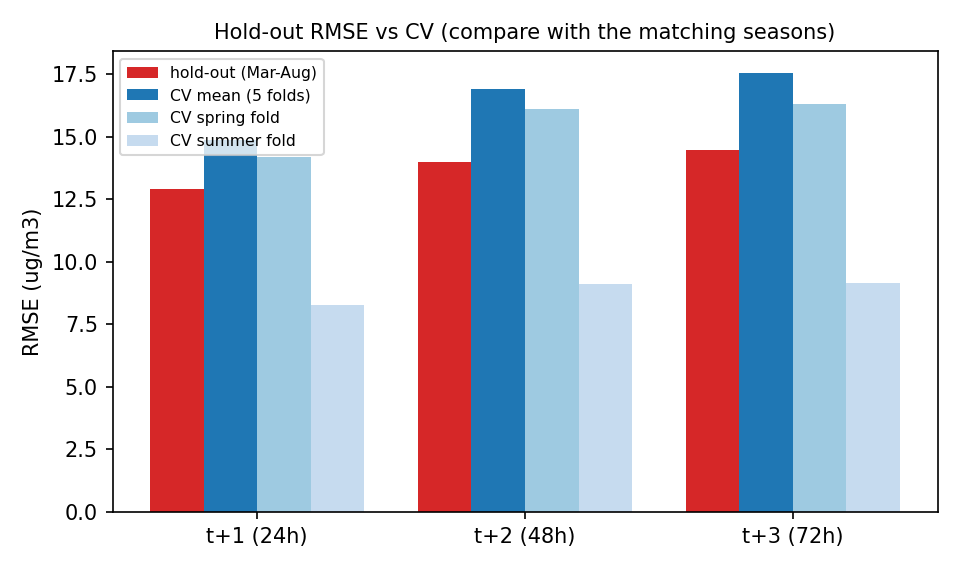

In [9]:
hr, hc, hv = rd("task6_holdout_reg.csv"), rd("task6_holdout_clf.csv"), rd("task6_holdout_vs_cv.csv"); hg = rd("task6_holdout_by_group.csv")
r = hr.copy(); r["horizon"] = r.horizon.map(H); r["rmse_95ci"] = r.apply(lambda x: f"[{x.rmse_ci95_low:.2f}, {x.rmse_ci95_high:.2f}]", axis=1)
print("REGRESSION"); display(r[["horizon", "model", "n", "rmse", "rmse_95ci", "mae", "r2", "bias", "rmse_persistence", "rmse_station_mean"]].round(2))
k = hc.copy(); k["horizon"] = k.horizon.map(H); k["recall_95ci"] = k.apply(lambda x: f"[{x.recall_ci95_low:.2f}, {x.recall_ci95_high:.2f}]", axis=1)
print("CLASSIFICATION at the fixed thresholds"); display(k[["horizon", "threshold", "risk_days", "alerts", "TP", "FP", "FN", "precision", "recall", "recall_95ci", "auc", "persistence_precision", "persistence_recall"]].round(3))
print("HOLD-OUT vs CV (compare with the spring and summer folds, not only the CV mean):"); display(hv.round(3))
display(Image(filename=str(FIG / "holdout_vs_cv.png"), width=520))

In [10]:
st = hg[(hg.task == "reg") & (hg.group_by == "station")].pivot_table(index="group", columns="horizon", values="rmse").round(2)
se = hg[(hg.task == "reg") & (hg.group_by == "season")].pivot_table(index="group", columns="horizon", values="rmse").round(2)
st.columns = se.columns = [H[int(x)] for x in st.columns]
print("Hold-out RMSE by station:"); display(st); print("by season (khamsin = Mar-May, other = Jun-Aug):"); display(se)
print("Alerts by season:"); display(hg[hg.task == "clf"][["horizon", "group", "n", "risk_days", "alerts", "precision", "recall"]].round(2))

Hold-out RMSE by station:


,t+1 (24h),t+2 (48h),t+3 (72h)
group,,,
downtown,10.79,11.36,12.40
helwan,15.76,16.92,17.26
new_cairo,9.16,10.03,10.72
october,15.41,17.04,17.11
shobra,12.13,13.23,13.75


by season (khamsin = Mar-May, other = Jun-Aug):


,t+1 (24h),t+2 (48h),t+3 (72h)
group,,,
khamsin,15.18,16.38,17.06
other,10.05,11.04,11.21


Alerts by season:


,horizon,group,n,risk_days,alerts,precision,recall
39,1,khamsin,460,95.0,23.0,0.74,0.18
40,1,other,445,35.0,0.0,NaN,0.00
41,2,khamsin,460,95.0,4.0,0.75,0.03
42,2,other,445,35.0,0.0,NaN,0.00
43,3,khamsin,460,95.0,5.0,0.40,0.02
44,3,other,445,35.0,0.0,NaN,0.00


**Reading of the hold-out**
- **No sign of over-fitting:** by season the hold-out RMSE matches the tuned CV (March-May 15.2 / 16.4 / 17.1 vs 14.2 / 16.2 / 16.6; June-August 10.0 / 11.0 / 11.2 vs 9.8 / 11.1 / 11.3). The overall hold-out RMSE is lower than the CV mean only because the hold-out has no winter.
- **t+1:** the regression is **not better than repeating today's value** (12.91 vs 12.84). At t+2 and t+3 it is 18% and 26% better.
- **Alert:** precision 0.74 at t+1, but recall only 0.13 / 0.02 / 0.02 (23 / 4 / 5 alerts for 130 risk days); no alert fired in June-August. The ranking quality holds (AUC 0.80 / 0.75 / 0.71) but the thresholds, set for precision 0.75 on winter-dominated folds, are too high for the warm months. They were **not** changed after seeing the hold-out.
- **Stations:** the October station is worse here (15.4 at t+1) than in the CV (13.2); Helwan stays hard.

## Limitations
- CV scores and thresholds were tuned on the same folds, so they are slightly optimistic.
- LightGBM vs XGBoost differences are within noise; the selection reflects serving cost, not a real accuracy gap.
- The hold-out has no winter and its 130 risk days are all in March-May: it confirms the regression, but says little about the alert in winter. Intervals are wide.
- Only an XGBoost classifier was tuned (Task 4).

## Reproduce
`python task6_01_evidence.py` -> `task6_02_select.py` -> `task6_03_train_save.py` -> `task6_04_register_mlflow.py` (team MLflow DB) -> `task6_05_score_holdout.py --confirm TASK6_FINAL_SCORING` (**once**) -> `task6_06_build_report.py`.